Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

1. $O(n)$ - cost of operation `dot_product += a[i] + b[i]` is $O(1)$ for n `i`s
2. $O(n^2)$ - `ans[i] += mat[i][j] * vec[j]`: essentially the dot product ($O(n)$) of n rows therefore $O(n*n)=O(n**2)$ 
3. $O(n^3)$ - `ans[i][j] += M[i][j] * N[j][i]`: result is an $n\times n$ matrix i.e. there are $n*n=n^2$ entries to compute, each entry is the dot product of the ith row and jth column, hence $O(n*n^2)=O(n^3)$

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [2]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

/var/folders/q2/f3q6c6p95xq9dy5bf2vnxm7c0000gn/T/ipykernel_95676/1108553842.py:5: RuntimeWarning: overflow encountered in scalar multiply
  return factorial(n - 1)*n


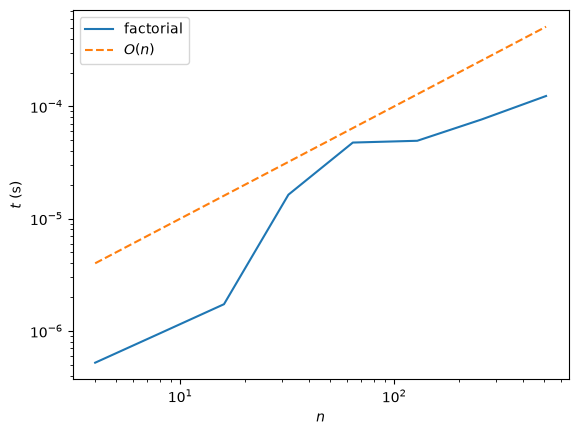

In [3]:
N = 2**np.arange(2, 10)

times = []
for n in N:
    t = %timeit -n4 -r3 -q -o factorial(n)
    times.append(t.best)

plt.loglog(N, times, label="factorial")
plt.loglog(N, 1e-6*N, '--', label=r'$O(n)$')

plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)

plt.show()

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [4]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [5]:
det = np.linalg.slogdet(A)

/Users/sophieperrot/Documents/Uni/PartIA-Computing-Michaelmas_szp22/venv/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/sophieperrot/Documents/Uni/PartIA-Computing-Michaelmas_szp22/venv/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/sophieperrot/Documents/Uni/PartIA-Computing-Michaelmas_szp22/venv/lib/python3.14/site-packages/numpy/linalg/_linalg.py:2349: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [6]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 12)

times = []
for n in N:
    A = np.random.rand(n, n)
    t = %timeit -q -o np.linalg.slogdet(A)
    times.append(t.best)

Plot result:

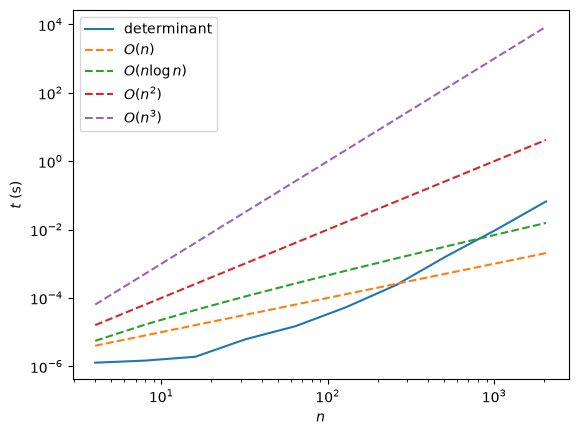

In [7]:
plt.loglog(N, times, label="determinant")
plt.loglog(N, 1e-6*N, '--', label=r'$O(n)$')
plt.loglog(N, 1e-6*N*np.log(N), '--', label=r'$O(n\log n)$')
plt.loglog(N, 1e-6*N**2, '--', label=r'$O(n^2)$')
plt.loglog(N, 1e-6*N**3, '--', label=r'$O(n^3)$')


plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)

plt.show()

From plot, determinant time complexity seems closest to $O(n^3)$